In [1]:
import numpy as np
import pandas as pd
import seaborn as sns

In [2]:
df = sns.load_dataset("iris")

df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
class Zscore:
    def __init__(self, np_columns: np.ndarray):
        self.mean = np.mean(np_columns)
        self.std = np.std(np_columns, ddof=0)

    def get_score(self, x):
        return abs(x - self.mean) / self.std

    def get_average_score(self, x):
        scores = self.get_score(x)
        return np.mean(scores)
    

score_calc_sepal_length = Zscore(df["sepal_length"])
scores_sepal_length = score_calc_sepal_length.get_score(df["sepal_length"])

score_calc_sepal_width = Zscore(df["sepal_width"])
scores_sepal_width = score_calc_sepal_width.get_score(df["sepal_width"])

score_calc_petal_length = Zscore(df["petal_length"])
scores_petal_length = score_calc_petal_length.get_score(df["petal_length"])

zdf = pd.DataFrame({'sepal_length':scores_sepal_length, 'sepal_width':scores_sepal_width, 'petal_length':scores_petal_length})
# print(scores_sepal_length, scores_sepal_width, scores_petal_length)

zdf.head()

,sepal_length,sepal_width,petal_length
0,0.900681,1.019004,1.340227
1,1.143017,0.131979,1.340227
2,1.385353,0.328414,1.397064
3,1.506521,0.098217,1.283389
4,1.021849,1.249201,1.340227


In [4]:
score_calc = Zscore(df["sepal_length"])
average_z_score = score_calc.get_average_score(df["sepal_length"])
print("Середнє значення z-scores для колонки 'sepal_length':", average_z_score)
score_calc = Zscore(df["sepal_width"])
average_z_score = score_calc.get_average_score(df["sepal_width"])
print("Середнє значення z-scores для колонки 'sepal_width':", average_z_score)
score_calc = Zscore(df["petal_length"])
average_z_score = score_calc.get_average_score(df["petal_length"])
print("Середнє значення z-scores для колонки 'petal_length':", average_z_score)

Середнє значення z-scores для колонки 'sepal_length': 0.8330964247836825
Середнє значення z-scores для колонки 'sepal_width': 0.7752617848895638
Середнє значення z-scores для колонки 'petal_length': 0.888224994511436


In [5]:
print(zdf['sepal_length'][zdf['sepal_length'] > 3].value_counts(), end="\n\n")

print(zdf['sepal_width'][zdf['sepal_width'] > 3].value_counts(), end="\n\n")

print(zdf['petal_length'][zdf['petal_length'] > 3].value_counts(), end="\n\n")

Series([], Name: count, dtype: int64)

sepal_width
3.090775    1
Name: count, dtype: int64

Series([], Name: count, dtype: int64)



In [6]:
import matplotlib.pyplot as plt

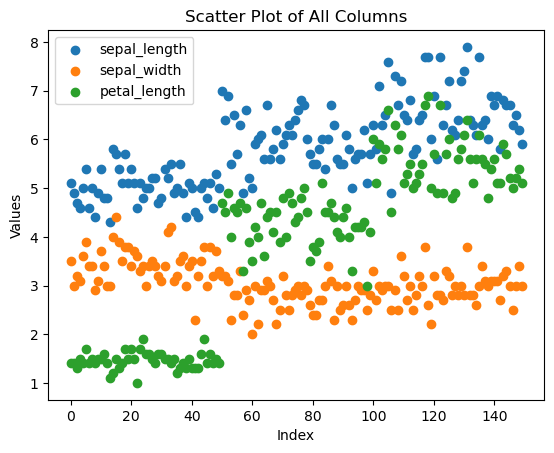

In [22]:
for column in df.columns:
    plt.scatter(df.index, df[column], label=column, marker='o')

# Adding title and labels
plt.title('Scatter Plot of All Columns')
plt.xlabel('Index')
plt.ylabel('Values')

# Show the legend
plt.legend()

# Show the plot
plt.show()

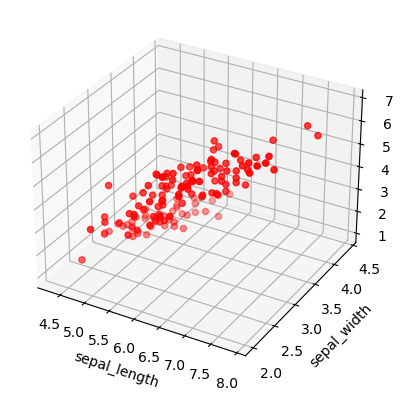

In [8]:
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Відображення трьох колонок на 3D графіку
ax.scatter(df['sepal_length'], df['sepal_width'], df['petal_length'], c='r', marker='o')

# Додавання підписів осей
ax.set_xlabel('sepal_length')
ax.set_ylabel('sepal_width')
ax.set_zlabel('petal_length')

# Відображення графіку
plt.show()

Можемо побачити, що набір данних є неперервним(відсутні nan), також можемо побачити що вони досить різноманітні.

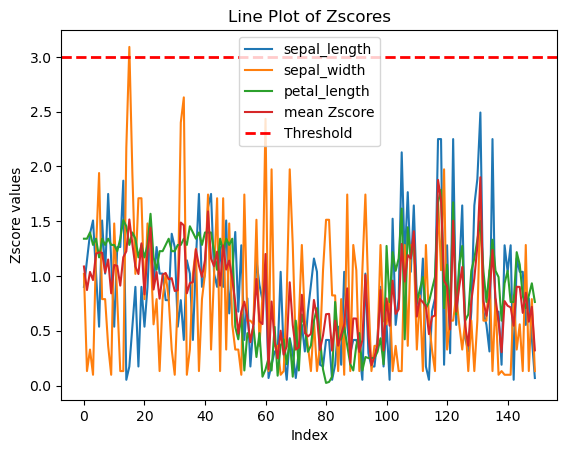

In [38]:
ax = zdf.plot()
plt.title('Line Plot of Zscores')
plt.xlabel('Index')
plt.ylabel('Zscore values')

# Adding a horizontal line at y=3
ax.axhline(y=3, color='r', linestyle='--', linewidth=2, label='Threshold')

# Show the plot with the added line
plt.legend()
plt.show()

Тут ми можемо побачити вже самі Z scores. Як видно з графіку, нетиповими (Zscore > 3) є лише 1 значення 1ї з колонок. Тому в подальшому як нетипові визначатиму найбільші 15 Zscore з кожного стовпця.

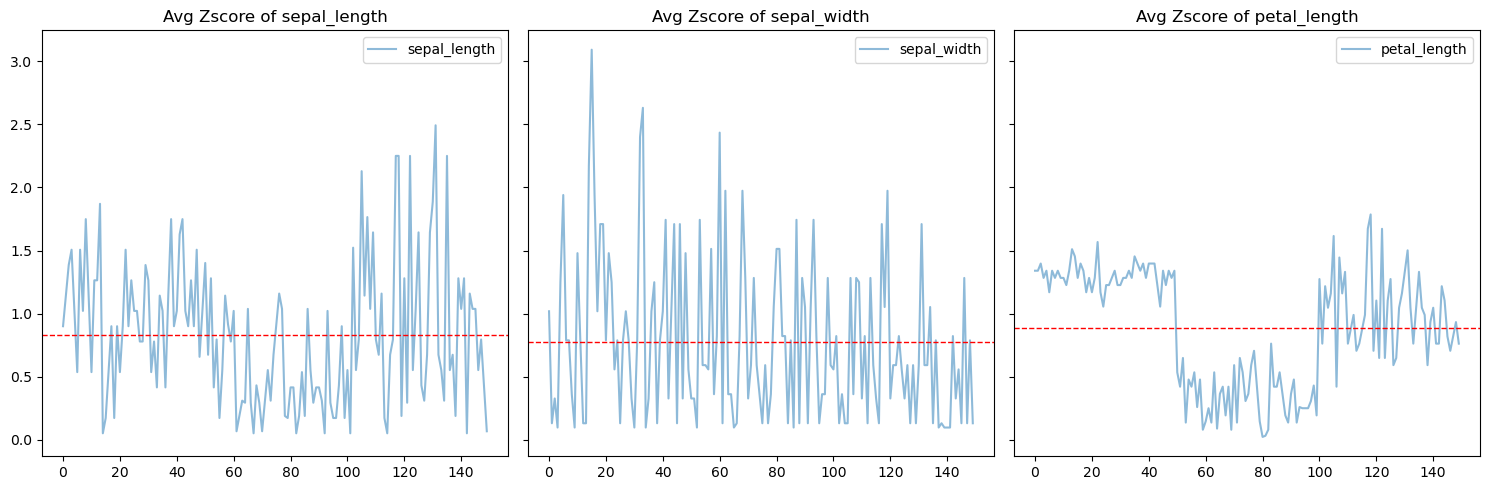

In [10]:
fig, axes = plt.subplots(nrows=1, ncols=len(zdf.columns), figsize=(15, 5), sharey=True)

for ax, column in zip(axes, zdf.columns):
    ax.plot(zdf[column], label=f'{column}', alpha=0.5)
    ax.set_title(f'Avg Zscore of {column}')
    ax.legend()

    ax.axhline(y=np.mean(zdf[column]), color='r', linestyle='--', linewidth=1, label='Avg')

plt.tight_layout()
plt.show()

Тут ми можемо побачити кожну з колонок, а точніше її Zscore - окремо. Червоною ж лінією позначено середнє значення(Агреговане). 

In [11]:
columns_to_drop = ['petal_width', 'species']
df = df.drop(columns=columns_to_drop)

На даних графіках показано найбільші Zscore для кожного з стовпців (Green 11-15, Yellow 6 - 10, Red 1 - 5).

In [14]:
zdf['mean Zscore'] = zdf.mean(axis=1)
zdf.head()

,sepal_length,sepal_width,petal_length,mean Zscore
0,0.900681,1.019004,1.340227,1.086637
1,1.143017,0.131979,1.340227,0.871741
2,1.385353,0.328414,1.397064,1.036944
3,1.506521,0.098217,1.283389,0.962709
4,1.021849,1.249201,1.340227,1.203759


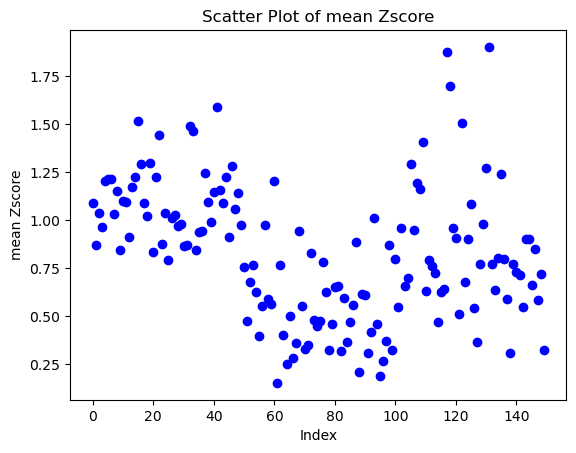

In [25]:
plt.scatter(zdf.index, zdf['mean Zscore'], color='blue', marker='o')

# Adding title and labels
plt.title('Scatter Plot of mean Zscore')
plt.xlabel('Index')
plt.ylabel('mean Zscore')

# Show the plot
plt.show()

Тут ми можемо бачити 3 колонки Zscore агреговані в 1(середнє) 

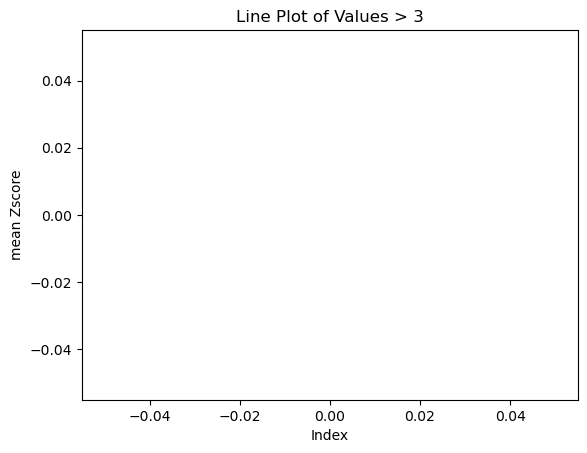

In [16]:
filtered_df = zdf[zdf['mean Zscore'] > 3]

# Plot the filtered column
filtered_df['mean Zscore'].plot(kind='line', marker='o')

# Adding title and labels
plt.title('Line Plot of Values > 3')
plt.xlabel('Index')
plt.ylabel('mean Zscore')

# Show the plot
plt.show()

Оскільки тут немає значень, то виведемо 15 найбільших

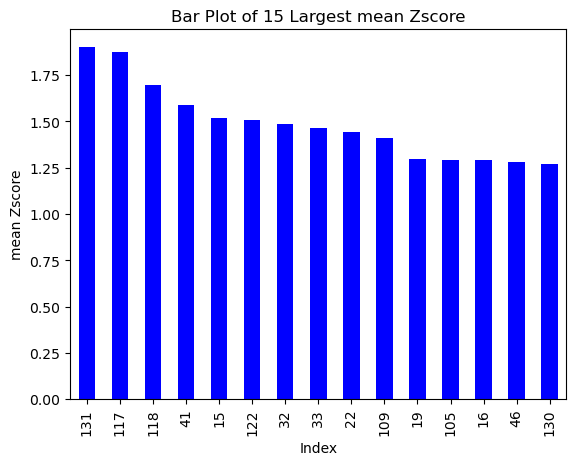

In [17]:
top_15_values = zdf.nlargest(15, 'mean Zscore')

# Plot the 15 largest values
top_15_values['mean Zscore'].plot(kind='bar', color='blue')

# Adding title and labels
plt.title('Bar Plot of 15 Largest mean Zscore')
plt.xlabel('Index')
plt.ylabel('mean Zscore')

# Show the plot
plt.show()

Можемо бачити 15 найбільших агрегованих Zscore

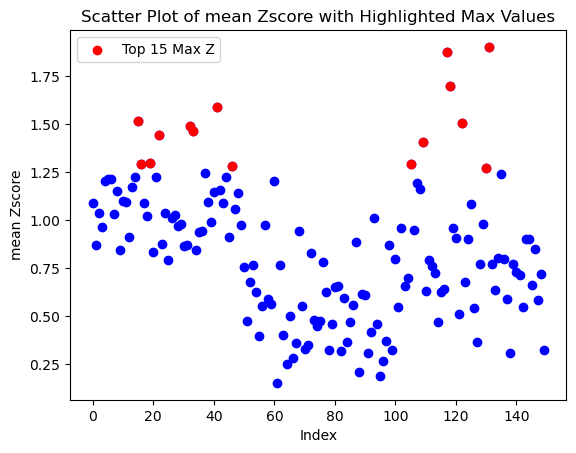

In [27]:
plt.scatter(zdf.index, zdf['mean Zscore'], color='blue', marker='o')

# Highlight the 15 largest values with red dots
max_values_indices = zdf['mean Zscore'].nlargest(15).index
plt.scatter(max_values_indices, zdf.loc[max_values_indices, 'mean Zscore'], color='red', label='Top 15 Max Z')

# Adding title and labels
plt.title('Scatter Plot of mean Zscore with Highlighted Max Values')
plt.xlabel('Index')
plt.ylabel('mean Zscore')

# Show the legend
plt.legend()

# Show the plot with highlighted points
plt.show()

Можемо бачити, що найбільші значення <2, а отже фактично нетипових данних у нас немає. Проте Я відобразив наші фейкові нетипові данні

In [29]:
at_row = np.argsort(zdf["mean Zscore"])[-15:]
at_row

135    130
136     46
137     16
138    105
139     19
140    109
141     22
142     33
143     32
144    122
145     15
146     41
147    118
148    117
149    131
Name: mean Zscore, dtype: int64

In [31]:
at_values = df.iloc[at_row]
at_values

,sepal_length,sepal_width,petal_length
130,7.4,2.8,6.1
46,5.1,3.8,1.6
16,5.4,3.9,1.3
105,7.6,3.0,6.6
19,5.1,3.8,1.5
109,7.2,3.6,6.1
22,4.6,3.6,1.0
33,5.5,4.2,1.4
32,5.2,4.1,1.5
122,7.7,2.8,6.7


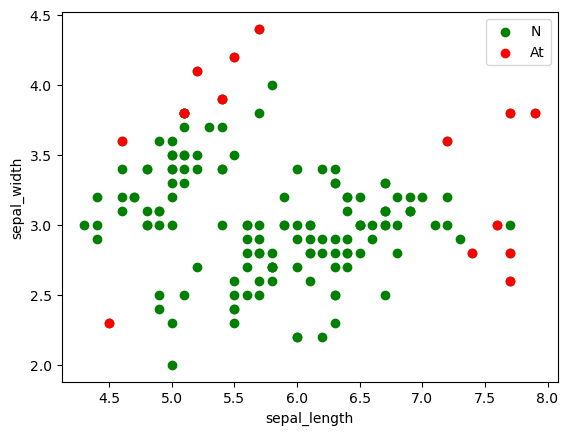

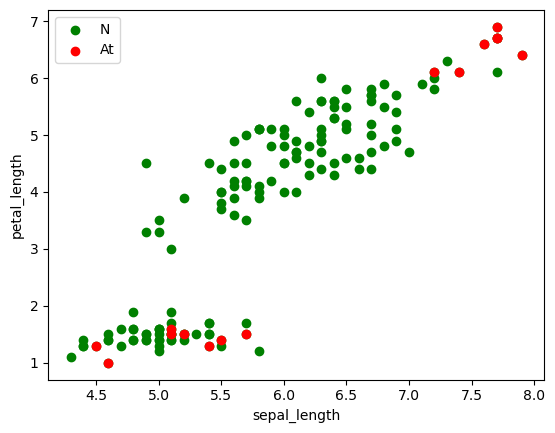

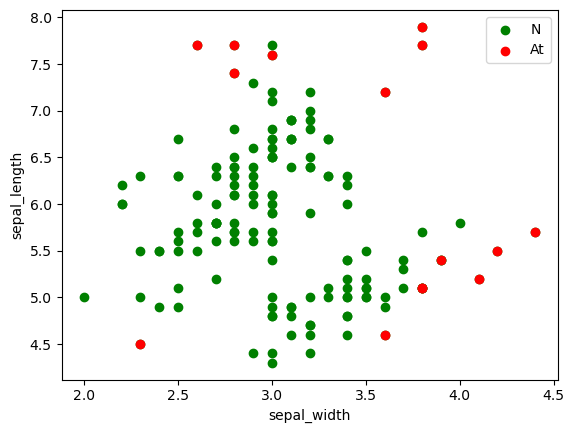

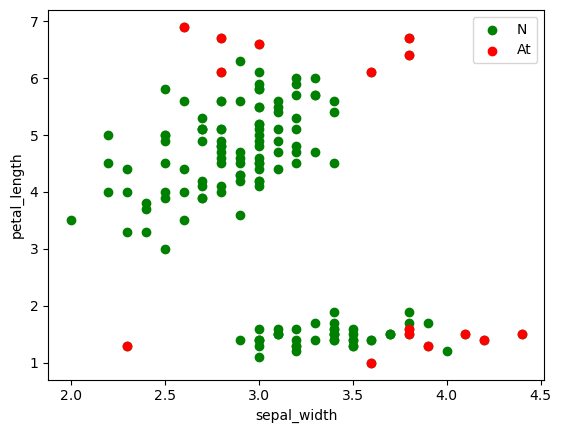

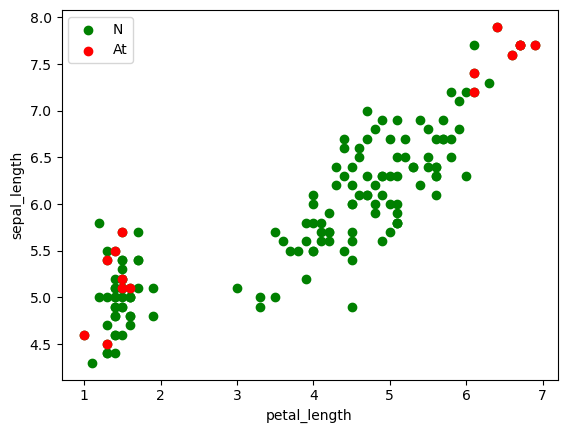

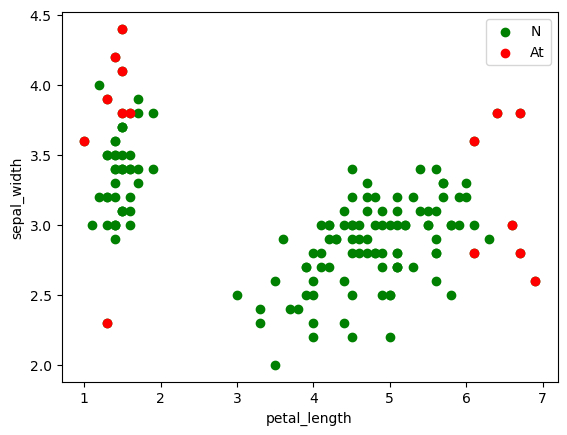

In [36]:
def draw1(columns):
  plt.figure()
  plt.scatter(df[columns[0]], df[columns[1]], c='green', label='N')
  plt.scatter(at_values[columns[0]], at_values[columns[1]], c='red', label='At')
  plt.xlabel(columns[0])
  plt.ylabel(columns[1])
  plt.legend()
  plt.show()

columns = ['sepal_length', 'sepal_width', 'petal_length']

for column in columns:

  for second_column in df.columns:
    if second_column == column:
      continue

    draw1([column, second_column])

Висновок : Спостерігаючи за графіками можемо сказати , що Ірис може мати нетипові співвідношення між різними своїми параметрами.
Проте існують і нетипові представники, параметри яких відрізняються від "загальноприйнятих".